# 02-1　自由粒子的波包：不確定性原理與 ħ → 0

**這一課打開了 $\hbar$。** 牛頓力學裡粒子有確定的位置和速度（等於設定 $\hbar = 0$）；
量子力學裡，粒子是一個波函數 $\psi(x,t)$，$|\psi|^2$ 是在 $x$ 找到它的機率密度。

這一課做四個實驗：

1. 看一個波包怎麼隨時間**散開**，並和解析公式比對
2. 數值驗證**不確定性原理** $\Delta x\,\Delta p \ge \hbar/2$
3. 檢查**機率守恆**（么正性，也就是黑洞資訊悖論裡被挑戰的那條原則）
4. 把 $\hbar$ 調小，看**牛頓力學怎麼回來**

## 理論

自由粒子（沒有位能）的薛丁格方程式：

$$i\hbar\,\frac{\partial\psi}{\partial t} = -\frac{\hbar^2}{2m}\frac{\partial^2\psi}{\partial x^2}$$

注意式子裡的 $t$：它是一個外部、絕對的時間參數，**就是牛頓的時間**。這正是量子力學保留下來、被廣義相對論拆掉的零件。

**高斯波包**（初始位置 $x_0$、寬度 $\sigma_0$、動量 $p_0$）：

$$\psi(x,0) = (2\pi\sigma_0^2)^{-1/4}\exp\!\left[-\frac{(x-x_0)^2}{4\sigma_0^2} + \frac{i p_0 x}{\hbar}\right]$$

它的寬度隨時間變大，有解析解：

$$\sigma(t) = \sigma_0\sqrt{1+\left(\frac{\hbar t}{2m\sigma_0^2}\right)^2}$$

**數值方法**：自由粒子在動量空間裡每個分量只是轉一個相位
$\tilde\psi(k,t) = \tilde\psi(k,0)\,e^{-i\hbar k^2 t/2m}$，
所以用 FFT 轉到動量空間、乘上相位、再轉回來，就是**精確解**，不用一步一步積分。
（下一課有位能時，會改用 split-step 方法。）

單位：取 $m = 1$；$\hbar$ 先設為 1，最後一個實驗再把它調小。

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = ["Microsoft JhengHei", "sans-serif"]  # 中文標籤
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 100

In [2]:
def make_grid(L=200.0, N=4096):
    # 位置網格 x 與對應的波數 k（FFT 用）
    x = np.linspace(-L / 2, L / 2, N, endpoint=False)
    dx = x[1] - x[0]
    k = 2 * np.pi * np.fft.fftfreq(N, d=dx)
    return x, dx, k


def gaussian(x, x0, sigma0, p0, hbar):
    return (2 * np.pi * sigma0**2) ** -0.25 * np.exp(
        -((x - x0) ** 2) / (4 * sigma0**2) + 1j * p0 * x / hbar
    )


def normalize(psi, dx):
    return psi / np.sqrt(np.sum(np.abs(psi) ** 2) * dx)


def evolve_free(psi0, k, t, hbar, m=1.0):
    # 自由粒子的精確時間演化：動量空間乘相位
    return np.fft.ifft(np.fft.fft(psi0) * np.exp(-1j * hbar * k**2 * t / (2 * m)))


def stats(psi, x, dx, k, hbar):
    # 回傳：總機率、<x>、Δx、<p>、Δp
    prob = np.abs(psi) ** 2
    norm = np.sum(prob) * dx
    mean_x = np.sum(x * prob) * dx / norm
    delta_x = np.sqrt(np.sum((x - mean_x) ** 2 * prob) * dx / norm)

    prob_k = np.abs(np.fft.fft(psi)) ** 2
    prob_k /= prob_k.sum()
    p = hbar * k
    mean_p = np.sum(p * prob_k)
    delta_p = np.sqrt(np.sum((p - mean_p) ** 2 * prob_k))
    return norm, mean_x, delta_x, mean_p, delta_p

## 實驗 1：波包散開

一個從 $x_0=-30$ 出發、動量 $p_0=1.5$ 往右跑的波包。牛頓力學的答案是「一個點以速度 1.5 等速前進」。

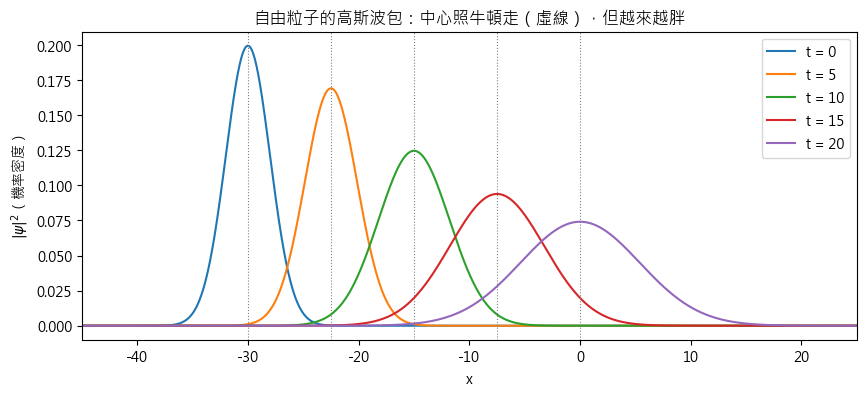

In [3]:
hbar, m = 1.0, 1.0
x0, sigma0, p0 = -30.0, 2.0, 1.5

x, dx, k = make_grid()
psi0 = gaussian(x, x0, sigma0, p0, hbar)

times = [0, 5, 10, 15, 20]
fig, ax = plt.subplots(figsize=(10, 4))
for t in times:
    psi_t = evolve_free(psi0, k, t, hbar, m)
    ax.plot(x, np.abs(psi_t) ** 2, label=f"t = {t}")
    ax.axvline(x0 + p0 / m * t, color="gray", ls=":", lw=0.8)  # 牛頓粒子的位置
ax.set_xlim(-45, 25)
ax.set_xlabel("x")
ax.set_ylabel(r"$|\psi|^2$（機率密度）")
ax.set_title("自由粒子的高斯波包：中心照牛頓走（虛線），但越來越胖")
ax.legend()
plt.show()

**觀察**：波包中心正好落在虛線上，也就是牛頓預測的位置；但波包越來越寬、越來越矮。
面積（總機率）不變，只是攤開了。

這是量子力學和牛頓力學的第一個差別：**即使沒有任何外力，「粒子在哪裡」也會越來越不確定。**

## 實驗 2：和解析公式比對，並驗證不確定性原理

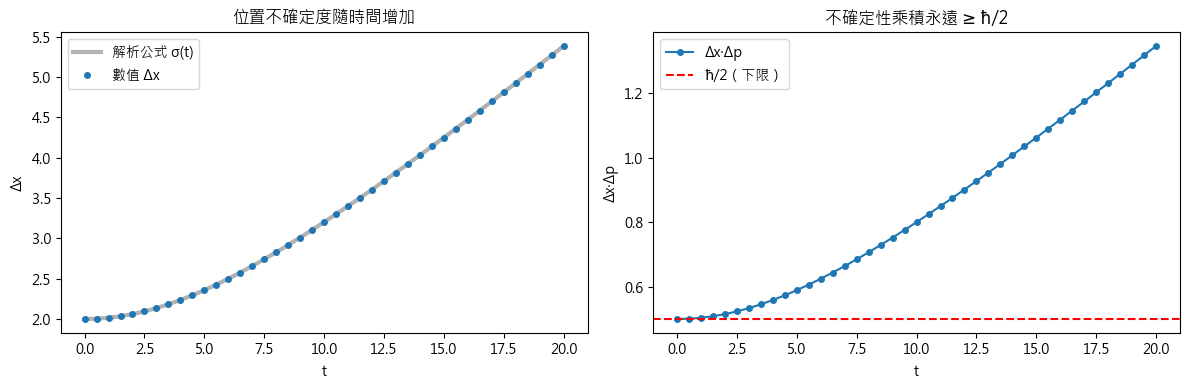

Δx 數值與解析解最大相對誤差：5.54e-16
Δp 在整段時間內：最小 0.250000，最大 0.250000（理論 ħ/2σ0 = 0.250000）
t=0 時 Δx·Δp / (ħ/2) = 1.000000


In [4]:
ts = np.linspace(0, 20, 41)
rows = [stats(evolve_free(psi0, k, t, hbar, m), x, dx, k, hbar) for t in ts]
norm_t, mx_t, Dx_t, mp_t, Dp_t = map(np.array, zip(*rows))
Dx_theory = sigma0 * np.sqrt(1 + (hbar * ts / (2 * m * sigma0**2)) ** 2)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ts, Dx_theory, "k-", lw=3, alpha=0.3, label="解析公式 σ(t)")
axes[0].plot(ts, Dx_t, "o", ms=4, label="數值 Δx")
axes[0].set_xlabel("t")
axes[0].set_ylabel("Δx")
axes[0].set_title("位置不確定度隨時間增加")
axes[0].legend()

axes[1].plot(ts, Dx_t * Dp_t, "o-", ms=4, label="Δx·Δp")
axes[1].axhline(hbar / 2, color="r", ls="--", label="ħ/2（下限）")
axes[1].set_xlabel("t")
axes[1].set_ylabel("Δx·Δp")
axes[1].set_title("不確定性乘積永遠 ≥ ħ/2")
axes[1].legend()
plt.tight_layout()
plt.show()

print(f"Δx 數值與解析解最大相對誤差：{np.max(np.abs(Dx_t - Dx_theory) / Dx_theory):.2e}")
print(f"Δp 在整段時間內：最小 {Dp_t.min():.6f}，最大 {Dp_t.max():.6f}（理論 ħ/2σ0 = {hbar / (2 * sigma0):.6f}）")
print(f"t=0 時 Δx·Δp / (ħ/2) = {Dx_t[0] * Dp_t[0] / (hbar / 2):.6f}")

**觀察**：

- 數值 $\Delta x$ 和解析公式吻合到數值誤差等級。
- $\Delta p$ **完全不變**：自由粒子不受力，動量分佈不會變。改變的是位置和動量之間的「相關性」，波包前緣跑得快、後緣跑得慢，所以越拉越開。
- $t=0$ 時乘積**剛好等於** $\hbar/2$：高斯波包是唯一能達到下限的形狀。之後乘積只會變大。

## 實驗 3：換別的形狀，乘積都比 ħ/2 大

不確定性原理說的是**所有**波函數都有 $\Delta x\Delta p \ge \hbar/2$。換幾種形狀試試：

- **sech 波包**：$\psi \propto \mathrm{sech}(x/a)$，理論值 $\Delta x\Delta p = \pi\hbar/6 \approx 0.524\,\hbar$
- **貓態**：兩個高斯波包的**疊加**，「同時在左邊和右邊」，正是上次討論「疊加態物質的引力場該指向哪裡」的那種狀態

形狀                    Δx        Δp     Δx·Δp/(ħ/2)
高斯                2.0000    0.2500          1.0000
sech              1.8138    0.2887          1.0472
貓態（相距 10）         5.2866    0.2146          2.2692
貓態（相距 30）        15.1327    0.2500          7.5664


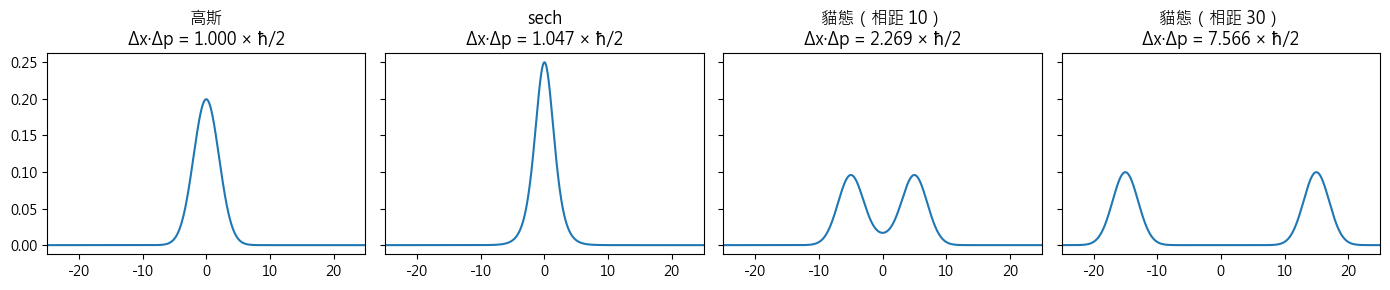


sech 理論值：π/3 = 1.0472（以 ħ/2 為單位）


In [5]:
x, dx, k = make_grid()
shapes = {
    "高斯": gaussian(x, 0, 2.0, 0, hbar),
    "sech": normalize(1 / np.cosh(x / 2.0), dx),
    "貓態（相距 10）": normalize(gaussian(x, -5, 2.0, 0, hbar) + gaussian(x, 5, 2.0, 0, hbar), dx),
    "貓態（相距 30）": normalize(gaussian(x, -15, 2.0, 0, hbar) + gaussian(x, 15, 2.0, 0, hbar), dx),
}

fig, axes = plt.subplots(1, len(shapes), figsize=(14, 3), sharey=True)
print(f"{'形狀':<14}{'Δx':>10}{'Δp':>10}{'Δx·Δp/(ħ/2)':>16}")
for ax, (name, psi) in zip(axes, shapes.items()):
    _, _, Dx, _, Dp = stats(psi, x, dx, k, hbar)
    print(f"{name:<14}{Dx:>10.4f}{Dp:>10.4f}{Dx * Dp / (hbar / 2):>16.4f}")
    ax.plot(x, np.abs(psi) ** 2)
    ax.set_xlim(-25, 25)
    ax.set_title(f"{name}\nΔx·Δp = {Dx * Dp / (hbar / 2):.3f} × ħ/2")
plt.tight_layout()
plt.show()

print(f"\nsech 理論值：π/3 = {np.pi / 3:.4f}（以 ħ/2 為單位）")

**觀察**：沒有任何形狀能低於 1（以 $\hbar/2$ 為單位），高斯剛好是 1，其他都比較大。
貓態的 $\Delta x$ 很大，因為粒子「同時在兩個地方」，兩團分得越開，位置就越不確定。

有個細節：相距 10 的貓態，$\Delta p$（0.215）反而比單一高斯（0.25）**小**。原因是兩團在動量空間會**干涉**，形成條紋，把動量分佈壓窄了一點。即使如此，$\Delta x$ 變大的幅度更多，乘積仍然遠高於下限。不確定性原理限制的是乘積，不是單獨哪一個量。

## 實驗 4：機率守恆（么正性）

量子力學的時間演化是**么正**的：總機率永遠是 1，資訊不會消失。
黑洞蒸發看起來違反了這條原則，這就是資訊悖論。這裡先確認一般情況下它成立：

In [6]:
print(f"t ∈ [0, 20] 期間總機率：最小 {norm_t.min():.15f}，最大 {norm_t.max():.15f}")
print(f"偏離 1 的最大量：{np.max(np.abs(norm_t - 1)):.1e}（只剩浮點誤差）")

# 么正性代表可逆：往前演化 20，再往回演化 20，應該完全回到原狀
psi_back = evolve_free(evolve_free(psi0, k, 20, hbar, m), k, -20, hbar, m)
print(f"前進 20 再倒退 20，和初始態的最大差異：{np.max(np.abs(psi_back - psi0)):.1e}")

t ∈ [0, 20] 期間總機率：最小 1.000000000000000，最大 1.000000000000000
偏離 1 的最大量：4.4e-16（只剩浮點誤差）
前進 20 再倒退 20，和初始態的最大差異：1.2e-16


**意義**：波包雖然散開了，看起來「資訊變模糊」，但其實**一點都沒丟**，倒轉時間就能完整還原。
資訊悖論的難題就在這裡：黑洞蒸發後只剩熱輻射，似乎沒辦法還原。

## 實驗 5：把 ħ 調小，牛頓力學回來了

固定質量、初始寬度和**動量** $p_0$，只把 $\hbar$ 從 1 調到 0.1、0.01。

（$\hbar$ 越小，波長 $\lambda = 2\pi\hbar/p_0$ 越短，所以網格要更密：這裡用 $N = 2^{14}$。）

ħ = 1.0    t=20 時 Δx = 5.3852，Δp = 0.25000


ħ = 0.1    t=20 時 Δx = 2.0616，Δp = 0.02500
ħ = 0.01   t=20 時 Δx = 2.0006，Δp = 0.00250


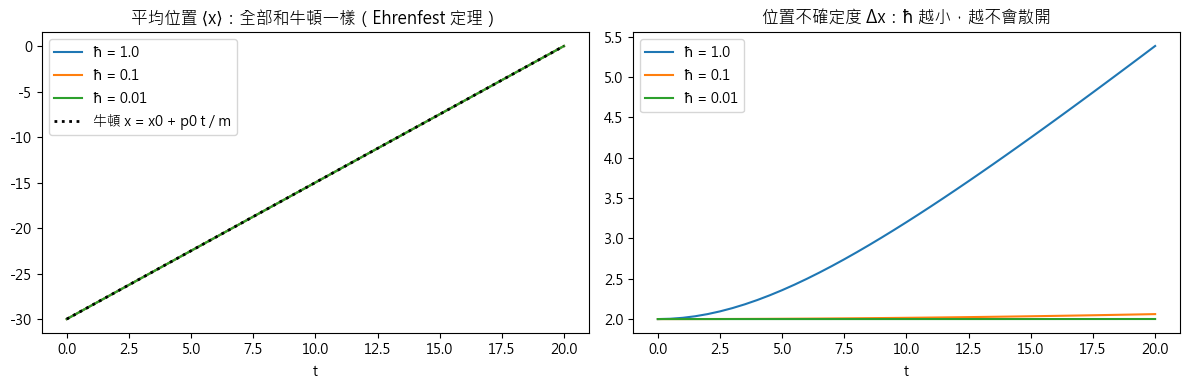

In [7]:
x, dx, k = make_grid(L=200.0, N=2**14)
ts = np.linspace(0, 20, 41)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for h in [1.0, 0.1, 0.01]:
    psi_h = gaussian(x, x0, sigma0, p0, h)
    res = np.array([stats(evolve_free(psi_h, k, t, h, m), x, dx, k, h) for t in ts])
    axes[0].plot(ts, res[:, 1], label=f"ħ = {h}")
    axes[1].plot(ts, res[:, 2], label=f"ħ = {h}")
    print(f"ħ = {h:<5}  t=20 時 Δx = {res[-1, 2]:.4f}，Δp = {res[-1, 4]:.5f}")

axes[0].plot(ts, x0 + p0 / m * ts, "k:", lw=2, label="牛頓 x = x0 + p0 t / m")
axes[0].set_title("平均位置 ⟨x⟩：全部和牛頓一樣（Ehrenfest 定理）")
axes[0].set_xlabel("t")
axes[0].legend()
axes[1].set_title("位置不確定度 Δx：ħ 越小，越不會散開")
axes[1].set_xlabel("t")
axes[1].legend()
plt.tight_layout()
plt.show()

**觀察**：

- 平均位置 $\langle x\rangle$ **完全照牛頓走**，不管 $\hbar$ 是多少。
- $\hbar$ 越小，$\Delta p = \hbar/2\sigma_0$ 越小，波包就越不會散開。$\hbar = 0.01$ 時，寬度在整段時間裡幾乎不變。
- 極限 $\hbar \to 0$：波包變成一個**不會散開、沿著古典軌道走的點**，這就是牛頓力學。

所以牛頓力學不是錯的，它是量子力學在 $\hbar \to 0$ 時的極限。
現實中 $\hbar \approx 1.05\times10^{-34}\ \mathrm{J\cdot s}$，對一顆棒球來說小到完全可以忽略，所以我們在日常生活中看不到量子效應。

## 動畫：波包散開

In [8]:
from matplotlib import animation
from IPython.display import HTML

hbar = 1.0
x, dx, k = make_grid()
psi0 = gaussian(x, x0, sigma0, p0, hbar)

fig, ax = plt.subplots(figsize=(8, 3), dpi=70)
line_prob, = ax.plot([], [], lw=2, label=r"$|\psi|^2$")
line_re, = ax.plot([], [], lw=0.8, alpha=0.6, label=r"Re $\psi$")
dot = ax.axvline(x0, color="gray", ls=":")
ax.set_xlim(-45, 25)
ax.set_ylim(-0.3, 0.3)
ax.set_xlabel("x")
ax.legend(loc="upper right")
title = ax.set_title("")

def frame(i):
    t = i * 0.5
    psi_t = evolve_free(psi0, k, t, hbar, m)
    line_prob.set_data(x, np.abs(psi_t) ** 2)
    line_re.set_data(x, psi_t.real * 0.5)
    dot.set_xdata([x0 + p0 / m * t])
    title.set_text(f"t = {t:.1f}　（虛線：牛頓粒子）")
    return line_prob, line_re, dot, title

anim = animation.FuncAnimation(fig, frame, frames=41, interval=80, blit=True)
plt.close(fig)
HTML(anim.to_jshtml())

（Re $\psi$ 是波函數的實部，縮小一半畫出來。可以看到波包前緣的波長比後緣短：前面跑得比較快的，正是動量比較大的成分。）

## 總結

| 實驗 | 結果 | 和大問題的關係 |
|---|---|---|
| 波包散開 | 沒有外力，位置也會越來越不確定 | 量子世界的基本特徵 |
| 不確定性原理 | 所有形狀都 $\Delta x\Delta p \ge \hbar/2$，高斯剛好等於 | 不能同時精確知道位置和動量 |
| 貓態 | 疊加態的 $\Delta x$ 很大 | 疊加態物質的引力場該是什麼？（05 單元） |
| 機率守恆 | 總機率不變、時間可倒轉 | 么正性，黑洞資訊悖論的核心 |
| $\hbar \to 0$ | $\langle x\rangle$ 照牛頓走，波包不再散開 | 牛頓力學是量子力學的極限 |

而貫穿整課的那個 $t$，是一個外在的、絕對的時間參數，到 04、05 單元會看到廣義相對論不允許這種東西存在。

## 練習

1. 把 `sigma0` 改成 0.5 和 5，波包散開的速度怎麼變？用解析公式解釋：越窄的波包為什麼散得越快？
2. 實驗 3 再加一種形狀，例如 `normalize(np.exp(-np.abs(x)), dx)`，乘積是多少？
3. 估算一顆 0.15 kg 的棒球，初始位置不確定度 1 μm，要過多久 $\Delta x$ 才會變成兩倍？（提示：令 $\hbar t / 2m\sigma_0^2 = \sqrt{3}$。）